[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/stocks.ipynb)

# Stock-market correlations, 2005 to 2024

This tutorial applies timecorr to 20 years of daily returns of 49 US industries. You will see how the correlations between industries change over time and rise around market crises, what `tc.features` computes at orders 1 to 3 on these data, and how to turn the dynamic correlations into a video of the market as a network.

**Data.** The daily value-weighted returns of the "49 Industry Portfolios" of the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) (built from the CRSP database; free to download, no key). Each NYSE, AMEX and NASDAQ stock is assigned to one of 49 industries by its SIC code at the end of June of each year ([details](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_49_ind_port.html)). Because the portfolios are rebuilt every year from the stocks listed at the time, the series have no gaps when a company is delisted. The notebook downloads them (about 4 MB) into a cache folder, set by the `TIMECORR_DATA` environment variable (default `~/timecorr_data`). The library updates the file every month; delete the cached copy to get a newer one.

The notebook runs in 1 to 2 minutes on a 12-core laptop and took 10.5 minutes on a Colab CPU runtime with 2 cores; the last cell prints its run time.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
# bottleneck>=1.5: pandas 3, which the tutorial extras install, warns about the older
# bottleneck that Colab has.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr[tutorials]>=0.3.1" "bottleneck>=1.5" || pip install -q "timecorr[tutorials] @ git+https://github.com/ContextLab/timecorr.git@master" "bottleneck>=1.5"

In [2]:
import io
import os
import re
import subprocess
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Video, display
from joblib import Parallel, delayed
from matplotlib.collections import LineCollection

import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
print('timecorr', tc.__version__)

timecorr 0.3.0


## 1. Downloading the returns

The cell below downloads the daily returns once; section 2 downloads the SIC code definitions the same way. A failed download says which file and where to look.

In [3]:
DATA_DIR = Path(os.environ.get('TIMECORR_DATA', Path.home() / 'timecorr_data')) / 'french'
DATA_DIR.mkdir(parents=True, exist_ok=True)
LIBRARY = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/'


def fetch(name):
    path = DATA_DIR / name
    if not path.exists():
        tmp = path.with_suffix('.part')
        try:
            urllib.request.urlretrieve(LIBRARY + 'ftp/' + name, tmp)
        except OSError as err:
            raise RuntimeError(f'could not download {LIBRARY}ftp/{name} ({err}); check that '
                               f'{LIBRARY}data_library.html still lists it') from err
        tmp.replace(path)
    return path


def read_text(name):
    with zipfile.ZipFile(fetch(name)) as z:
        return z.read(z.namelist()[0]).decode('latin-1')


returns_text = read_text('49_Industry_Portfolios_daily_CSV.zip')
print(returns_text.splitlines()[0])

This file was created using the 202609 CRSP database.


The file holds several tables; the first is the value-weighted daily returns, in percent. The cell keeps the trading days of 2005 to 2024 and converts each return `r` to a log return, `log(1 + r / 100)`. The library marks missing values with -99.99 or -999; the cell counts them and drops any industry that has one.

In [4]:
lines = returns_text.splitlines()
first = next(i for i, line in enumerate(lines) if 'Average Value Weighted Returns -- Daily' in line)
last = next(i for i in range(first + 1, len(lines)) if not lines[i].strip())
table = pd.read_csv(io.StringIO('\n'.join(lines[first + 1:last])), index_col=0)
table.index = pd.to_datetime(table.index.astype(str).str.strip(), format='%Y%m%d')
table.columns = table.columns.str.strip()
table = table.loc['2005-01-01':'2024-12-31']

missing = (table <= -99.99).sum()
print(f'missing values: {missing.sum()}')
table = table.loc[:, missing == 0]
returns = np.log1p(table / 100)
dates = returns.index
industries = list(returns.columns)
print(f'{len(dates)} trading days ({dates[0].date()} to {dates[-1].date()}), {len(industries)} industries')

missing values: 0
5033 trading days (2005-01-03 to 2024-12-31), 49 industries


## 2. Sectors

For plotting, each industry joins the group of the library's 12-industry classification that holds at least half of its SIC codes ("Other" if none does). The cell prints each industry's full name and sector.

In [5]:
def sic_groups(name):
    # {short name: (description, set of SIC codes)} from a Siccodes file
    groups, current = {}, None
    for line in read_text(name).splitlines():
        span = re.match(r'\s*(\d{4})-(\d{4})', line)
        head = re.match(r'\s*\d+\s+(\S+)\s+(.*\S)', line)
        if span and current:
            groups[current][1].update(range(int(span[1]), int(span[2]) + 1))
        elif head:
            current = head[1]
            groups[current] = (head[2], set())
    return groups


ind49, ind12 = sic_groups('Siccodes49.zip'), sic_groups('Siccodes12.zip')
SECTOR_NAMES = {'NoDur': 'Nondurables', 'Durbl': 'Durables', 'Manuf': 'Manufacturing',
                'Enrgy': 'Energy', 'Chems': 'Chemicals', 'BusEq': 'Business equipment',
                'Telcm': 'Telecom', 'Utils': 'Utilities', 'Shops': 'Shops',
                'Hlth': 'Health', 'Money': 'Finance', 'Other': 'Other'}
sector = {}
for name in industries:
    codes = ind49[name][1]
    overlap = {g: len(codes & c) for g, (_, c) in ind12.items()}
    best = max(overlap, key=overlap.get)
    sector[name] = SECTOR_NAMES[best if 2 * overlap[best] >= len(codes) else 'Other']

sectors = [s for s in SECTOR_NAMES.values() if s in sector.values()]
for s in sectors:
    print(f'{s:>18}: ' + ', '.join(f'{n} ({ind49[n][0].strip()})' for n in industries if sector[n] == s))

       Nondurables: Agric (Agriculture), Food (Food Products), Soda (Candy & Soda), Beer (Beer & Liquor), Smoke (Tobacco Products), Toys (Recreation), Books (Printing and Publishing), Clths (Apparel), Txtls (Textiles)
     Manufacturing: Rubbr (Rubber and Plastic Products), Steel (Steel Works Etc), FabPr (Fabricated Products), Mach (Machinery), ElcEq (Electrical Equipment), Autos (Automobiles and Trucks), Aero (Aircraft), Ships (Shipbuilding, Railroad Equipment), Guns (Defense), LabEq (Measuring and Control Equipment), Paper (Business Supplies), Boxes (Shipping Containers)
            Energy: Coal (Coal), Oil (Petroleum and Natural Gas)
         Chemicals: Chems (Chemicals)
Business equipment: Hardw (Computers), Softw (Computer Software), Chips (Electronic Equipment)
           Telecom: Telcm (Communication)
         Utilities: Util (Utilities)
             Shops: Whlsl (Wholesale), Rtail (Retail), Meals (Restaurants, Hotels, Motels)
            Health: Hlth (Healthcare), MedEq (Medica

## 3. Dynamic correlations

`tc.timecorr` estimates, at every trading day, the correlation between every pair of industries, weighting the surrounding days with a Gaussian kernel (the default; its parameters are printed below). The result has one row per day and one column per pair; `tc.vec2mat` turns it into a 49 by 49 matrix per day.

In [6]:
start = time.time()
corrs = tc.timecorr(returns.values)
C = tc.vec2mat(corrs)                          # (49, 49, days)
print(f'kernel: gaussian_weights {tc.gaussian_params}; result {corrs.shape} in {time.time() - start:.1f} s')

K = len(industries)
iu = np.triu_indices(K, 1)
pairs = C[iu[0], iu[1], :]                     # (pairs, days)
mean_corr = pd.Series(pairs.mean(axis=0), index=dates)
same = np.array([sector[industries[i]] == sector[industries[j]] for i, j in zip(*iu)])

kernel: gaussian_weights {'var': 100}; result (5033, 1225) in 0.3 s


The plot shows the mean correlation over all pairs of industries, and separately over pairs within a sector and pairs in different sectors. The dashed lines mark three events:

- 15 September 2008: Lehman Brothers filed for bankruptcy ([Wikipedia](https://en.wikipedia.org/wiki/Bankruptcy_of_Lehman_Brothers)).
- 5 August 2011: Standard & Poor's lowered the credit rating of the United States from AAA to AA+ ([Wikipedia](https://en.wikipedia.org/wiki/United_States_federal_government_credit-rating_downgrades)).
- 11 March 2020: the World Health Organization assessed that COVID-19 can be characterized as a pandemic ([WHO timeline](https://www.who.int/news/item/27-04-2020-who-timeline---covid-19)).

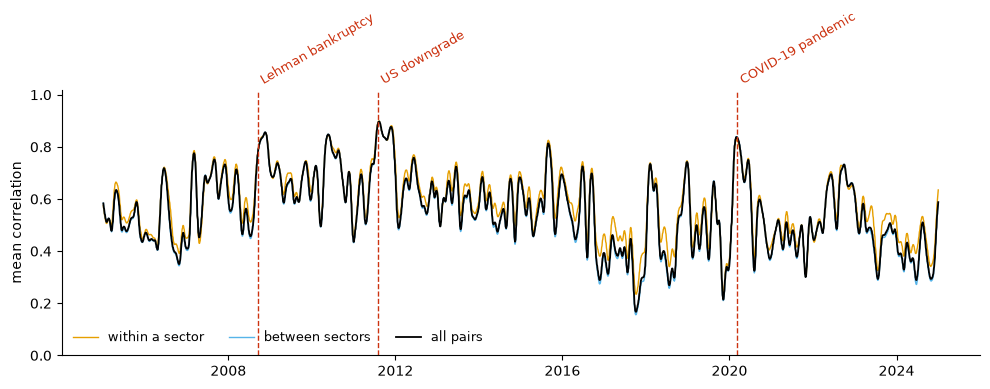

In [7]:
EVENTS = {'Lehman bankruptcy': '2008-09-15', 'US downgrade': '2011-08-05', 'COVID-19 pandemic': '2020-03-11'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 100})

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates, pairs[same].mean(axis=0), color='#E69F00', lw=1, label='within a sector')
ax.plot(dates, pairs[~same].mean(axis=0), color='#56B4E9', lw=1, label='between sectors')
ax.plot(dates, mean_corr, color='black', lw=1.3, label='all pairs')
for label, day in EVENTS.items():
    ax.axvline(pd.Timestamp(day), color='#CC3311', ls='--', lw=1)
    ax.text(pd.Timestamp(day), 1.03, label, color='#CC3311', fontsize=9, rotation=30,
            ha='left', va='bottom')
ax.set_ylim(0, 1.02)
ax.set_ylabel('mean correlation')
ax.legend(loc='lower left', ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

The table checks each event against the curve: the mean correlation on the event day, its largest value in the following 30 trading days, and the share of all days in 2005 to 2024 with a lower value than that peak.

In [8]:
rows = []
for label, day in EVENTS.items():
    t0 = dates.searchsorted(pd.Timestamp(day))
    window = mean_corr.iloc[t0:t0 + 30]
    rows.append({'event': label, 'date': dates[t0].date(), 'on the day': window.iloc[0],
                 'peak in next 30 days': window.max(), 'peak date': window.idxmax().date(),
                 'days below the peak (%)': 100 * (mean_corr < window.max()).mean()})
print(f'median over all days: {mean_corr.median():.2f}')
print(pd.DataFrame(rows).round(2).to_string(index=False))

median over all days: 0.55
            event       date  on the day  peak in next 30 days  peak date  days below the peak (%)
Lehman bankruptcy 2008-09-15        0.77                  0.84 2008-10-24                    97.26
     US downgrade 2011-08-05        0.90                  0.90 2011-08-11                    99.98
COVID-19 pandemic 2020-03-11        0.83                  0.83 2020-03-11                    97.04


The matrices of the calmest and the most correlated day of the period (lowest and highest mean correlation), averaged within and between sectors:

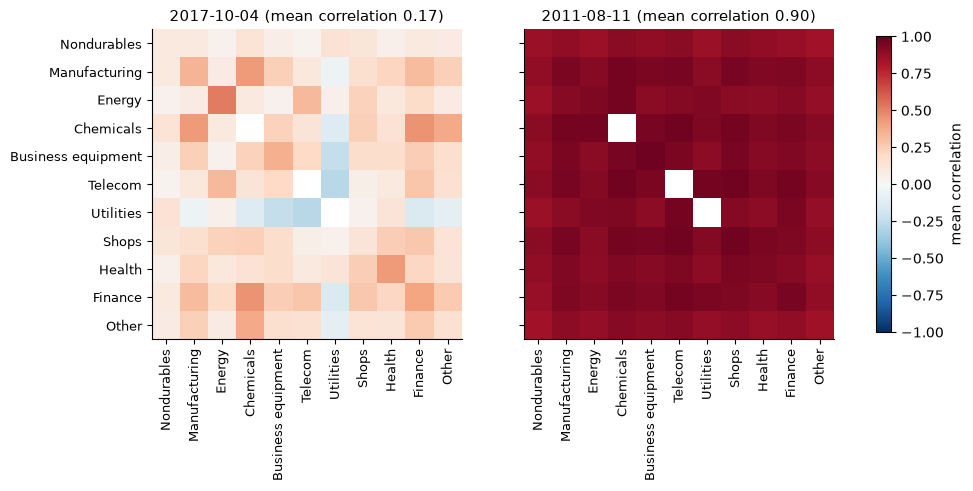

In [9]:
groups = [[i for i, n in enumerate(industries) if sector[n] == s] for s in sectors]
off_diagonal = ~np.eye(K, dtype=bool)


def sector_matrix(t):
    # mean correlation between the industries of two sectors (pairs of distinct industries;
    # blank for a one-industry sector with itself)
    M = np.full((len(groups), len(groups)), np.nan)
    for a, ga in enumerate(groups):
        for b, gb in enumerate(groups):
            values = C[np.ix_(ga, gb, [t])][off_diagonal[np.ix_(ga, gb)]]
            if values.size:
                M[a, b] = values.mean()
    return M


fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, t in zip(axes, [int(mean_corr.argmin()), int(mean_corr.argmax())]):
    im = ax.imshow(sector_matrix(t), vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(sectors)), sectors, rotation=90, fontsize=9)
    ax.set_yticks(range(len(sectors)), sectors if ax is axes[0] else [], fontsize=9)
    ax.set_title(f'{dates[t].date()} (mean correlation {mean_corr.iloc[t]:.2f})', fontsize=11)
fig.colorbar(im, ax=axes, shrink=0.8, label='mean correlation')
plt.show()

## 4. Higher-order features

`tc.features(data, order=3)` repeats the correlation step: the features of order `k` describe how the order `k - 1` features co-vary over time. With `return_info=True` it also returns a record of each step (see the [higher-order tutorial](higher_order.ipynb) and the API docs of `tc.features` for the two paths). The cell prints, for each step, its input and output widths and the reducer it used.

In [10]:
start = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
    X, info = tc.features(returns.values, order=3, return_info=True)
caught = [w for w in caught if issubclass(w.category, UserWarning)]  # timecorr's warnings only
print(f'tc.features: {time.time() - start:.0f} s')
for w in caught:
    print(f'{w.category.__name__}: {w.message}')
print(f'\n{"order":>5} {"path":>9} {"input":>6} {"output":>7}  reducer used')
for step in info:
    note = f'  (fallback: {step["fallback"]})' if step.get('fallback') else ''
    print(f'{step["order"]:>5} {step["path"]:>9} {step["input_width"]:>6} {step["output_width"]:>7}  '
          f'{step["effective"]}{note}')

tc.features: 1 s

order      path  input  output  reducer used
    1  analysis     49      49  PCA
    1   feeding     49       9  Communities(n=None, signed=False, n_null=5)
    2  analysis      9      18  WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)
    2   feeding      9       9  WeightedStrength(split=False, signed=False, n=None, n_null=5, center=False)  (fallback: too_few_community_columns)
    3  analysis      9      18  WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)


What each order holds (the record above names the reducer of each step):

- `X[0]` is the returns themselves.
- `X[1]` reduces the day-by-day correlations of section 3 with PCA: column 1 is the direction along which the pair correlations vary most.
- The feeding path summarizes correlations for the next order (`D[1]`, `D[2]`). A `Communities()` step gives one column per community of inputs: the mean squared correlation within it.
- `X[2]` and `X[3]` come from `WeightedStrength(signed=True)`: the first half of the columns are magnitudes (how strongly each input co-varies with the others at that moment), the second half signed values.

The communities found at each feeding step that used `Communities()` (the cell runs `tc.features` again with an explicit `tc.Communities()`, which records them, and checks that the output is unchanged):

In [11]:
community_orders = [s['order'] for s in info
                    if s['path'] == 'feeding' and s['effective'].startswith('Communities')]
explicit = {k: tc.Communities() for k in community_orders}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # the same warnings as above
    X_check = tc.features(returns.values, order=3, delta_rfun=explicit or 'auto')
print('same output as the default run:', all(np.array_equal(a, b) for a, b in zip(X, X_check)))
for k in community_orders:
    labels = explicit[k].fits_[-1]['labels']
    if k == 1:
        for c in np.unique(labels):
            print(f'D[1] community {c + 1}: ' + ', '.join(np.array(industries)[labels == c]))
    else:
        print(f'D[{k}] community sizes: {np.bincount(labels).tolist()}')

same output as the default run: True
D[1] community 1: Agric
D[1] community 2: Food, Soda, Beer, Hshld, Util
D[1] community 3: Smoke
D[1] community 4: Toys, Fun, Clths, Rtail, Meals
D[1] community 5: Books, Txtls, Cnstr, FabPr, Autos, Aero, Ships, PerSv, RlEst
D[1] community 6: Hlth, MedEq, Drugs
D[1] community 7: Chems, BldMt, Mach, ElcEq, Paper, Boxes, Trans
D[1] community 8: Rubbr, BusSv, LabEq, Whlsl
D[1] community 9: Steel, Mines, Coal, Oil
D[1] community 10: Guns
D[1] community 11: Gold
D[1] community 12: Telcm, Banks, Insur, Fin, Other
D[1] community 13: Hardw, Softw, Chips


How closely each order follows the market-wide level of correlation: the cell prints the correlation over days between the mean correlation of section 3 and the first column of `X[1]`, and between it and the mean of the magnitude columns of `X[2]` and `X[3]`. The sign of a PCA column is arbitrary. The first column of `X[1]` tracks the market-wide level; the higher orders follow it much less.

          X[1], column 1: correlation with the mean correlation +1.00
    X[2], mean magnitude: correlation with the mean correlation +0.26
    X[3], mean magnitude: correlation with the mean correlation +0.01


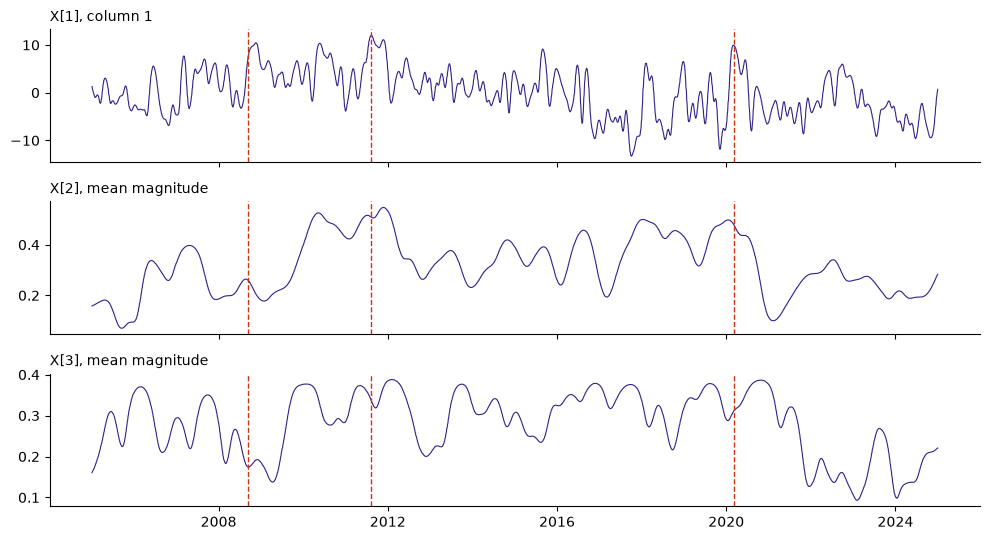

In [12]:
summaries = {'X[1], column 1': X[1][:, 0]}
for k in (2, 3):
    assert any(s['order'] == k and s['path'] == 'analysis' and s['effective'].startswith('WeightedStrength')
               and 'signed=True' in s['effective'] for s in info)
    summaries[f'X[{k}], mean magnitude'] = X[k][:, :X[k].shape[1] // 2].mean(axis=1)

fig, axes = plt.subplots(len(summaries), 1, figsize=(10, 5.5), sharex=True)
for ax, (label, series) in zip(axes, summaries.items()):
    print(f'{label:>24}: correlation with the mean correlation {np.corrcoef(series, mean_corr)[0, 1]:+.2f}')
    ax.plot(dates, series, color='#332288', lw=0.8)
    for day in EVENTS.values():
        ax.axvline(pd.Timestamp(day), color='#CC3311', ls='--', lw=1)
    ax.set_title(label, fontsize=10, loc='left')
plt.tight_layout()
plt.show()

## 5. The market as a network

The video draws the 49 industries on a circle, grouped and colored by sector. At each frame, an edge joins two industries whose correlation that day is in the top 10% of all pair-day correlations of the period (the cutoff is printed below); edges are darker and thicker the closer the correlation is to 1. Node sizes grow with an industry's mean correlation with the others. The panel on the right follows the mean correlation over time.

Each frame shows one trading day, with no frames drawn in between: every 4th day (`STEP = 4`), at 30 frames per second. Frames are drawn in parallel (up to three workers) and encoded to H.264 (1920 x 1080) with the ffmpeg of `imageio-ffmpeg`. In the documentation the video is a linked file; elsewhere (for example on Colab) it is saved in `tutorial_media/` and shown inline.

In [13]:
CUTOFF = np.quantile(pairs, 0.9)
STEP, FPS, CRF = 4, 30, 27
FRAMES = np.arange(0, len(dates), STEP)
# Inside the documentation sources (docs/tutorial), videos go to docs/_static/tutorial_media and
# are linked; anywhere else (for example on Colab), they go to ./tutorial_media and are embedded.
IN_DOCS = (Path('..') / 'conf.py').exists() and (Path('..') / '_static').is_dir()
MEDIA_DIR = Path('..') / '_static' / 'tutorial_media' if IN_DOCS else Path('tutorial_media')
MEDIA_DIR.mkdir(parents=True, exist_ok=True)
CORES = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count() or 1  # usable cores
N_JOBS = min(3, CORES)                                      # parallel frame-drawing workers


def show_video(path):
    if IN_DOCS:
        src = Path(os.path.relpath(path)).as_posix()
        display(HTML(f'<video src="{src}" controls loop muted playsinline preload="metadata" '
                     f'style="width: 100%; max-width: 960px;"></video>'))
    else:
        display(Video(str(path), embed=True, width=960,
                      html_attributes='controls loop muted playsinline'))
print(f'edge cutoff: correlation >= {CUTOFF:.3f}; {len(FRAMES)} frames ({len(FRAMES) / FPS:.0f} s)')

# node positions: sectors in contiguous arcs separated by gaps
PALETTE = ['#CC6677', '#332288', '#DDCC77', '#117733', '#88CCEE', '#882255',
           '#44AA99', '#999933', '#AA4499', '#E69F00', '#999999']
color_of = dict(zip(sectors, PALETTE))
order = sorted(range(K), key=lambda i: (sectors.index(sector[industries[i]]), industries[i]))
slots, previous = [], None
for i in order:
    slots.append((slots[-1] + (1.6 if sector[industries[i]] != previous else 1)) if slots else 0)
    previous = sector[industries[i]]
angle = np.empty(K)
angle[order] = np.pi / 2 - 2 * np.pi * np.array(slots) / (slots[-1] + 1.6)
xy = np.c_[np.cos(angle), np.sin(angle)]
s = np.linspace(0, 1, 32)[:, None]
curves = np.array([(1 - s) ** 2 * xy[i] + 2 * (1 - s) * s * 0.3 * (xy[i] + xy[j]) / 2 + s ** 2 * xy[j]
                   for i, j in zip(*iu)])                # edges bend toward the center
strength = (C.sum(axis=1) - 1) / (K - 1)                 # (49, days): mean correlation with the others
EDGE_CMAP = plt.get_cmap('magma_r')


def draw_frame(t, path=None, dpi=100):
    fig = plt.figure(figsize=(19.2, 10.8), dpi=dpi, facecolor='white')
    ax = fig.add_axes([0.0, 0.0, 0.5625, 1.0])
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect('equal')
    ax.axis('off')
    on = np.flatnonzero(pairs[:, t] >= CUTOFF)
    on = on[np.argsort(pairs[on, t])]                    # strongest edges on top
    w = (pairs[on, t] - CUTOFF) / (1 - CUTOFF)
    colors = EDGE_CMAP(0.2 + 0.7 * w)
    colors[:, 3] = 0.1 + 0.6 * w
    ax.add_collection(LineCollection(curves[on], colors=colors, linewidths=0.4 + 1.8 * w))
    ax.scatter(*xy.T, s=40 + 400 * np.clip(strength[:, t], 0, 1) ** 2, zorder=3,
               c=[color_of[sector[n]] for n in industries], edgecolors='white', linewidths=1)
    for i, name in enumerate(industries):
        deg = np.degrees(angle[i]) % 360
        flip = 90 < deg < 270
        ax.text(*(1.08 * xy[i]), name, rotation=deg + 180 * flip, rotation_mode='anchor',
                ha='right' if flip else 'left', va='center', fontsize=13, color='#333333')
    fig.text(0.585, 0.92, 'Correlations between 49 US industries', fontsize=26, color='#222222')
    fig.text(0.585, 0.875, 'daily log returns; edges: correlation in the top 10% of the period',
             fontsize=15, color='#555555')
    fig.text(0.585, 0.77, dates[t].strftime('%d %B %Y'), fontsize=40, weight='bold', color='#111111')
    for j, name in enumerate(sectors):
        x, y = 0.6 + (j % 3) * 0.135, 0.69 - (j // 3) * 0.045
        fig.text(x, y, '●', color=color_of[name], fontsize=22, va='center')
        fig.text(x + 0.016, y, name, fontsize=15, va='center', color='#333333')
    fig.text(0.585, 0.48, 'Mean correlation over all pairs', fontsize=17, color='#222222')
    tax = fig.add_axes([0.6, 0.08, 0.37, 0.27])
    tax.plot(dates, mean_corr, color='#BBBBBB', lw=1)
    tax.plot(dates[:t + 1], mean_corr.iloc[:t + 1], color='#332288', lw=1.5)
    tax.axvline(dates[t], color='#CC3311', lw=2)
    for label, day in EVENTS.items():
        tax.axvline(pd.Timestamp(day), ymin=0.93, color='#555555', lw=1)
        tax.text(pd.Timestamp(day), 1.04, label, fontsize=12, color='#555555',
                 rotation=30, ha='left', va='bottom')
    tax.set_ylim(0, 1)
    tax.tick_params(labelsize=13)
    for side in ('top', 'right'):
        tax.spines[side].set_visible(False)
    if path is None:
        return fig
    fig.savefig(path, dpi=dpi, facecolor='white', pil_kwargs={'compress_level': 1})  # read once by ffmpeg
    plt.close(fig)

edge cutoff: correlation >= 0.839; 1259 frames (42 s)


A still frame: the most correlated day of the period.

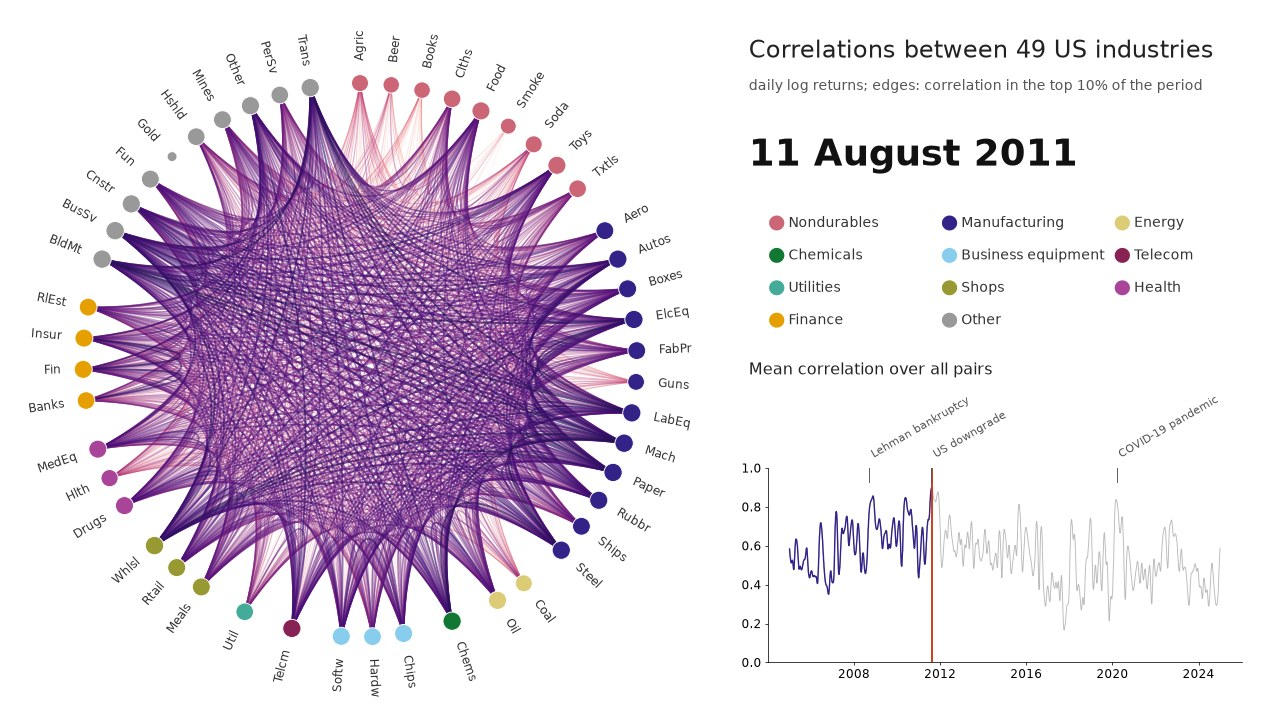

In [14]:
fig = draw_frame(int(mean_corr.argmax()), dpi=100)
buf = io.BytesIO()
fig.savefig(buf, format='jpeg', dpi=2 / 3 * 100, pil_kwargs={'quality': 88})
plt.close(fig)
display(Image(data=buf.getvalue(), format='jpeg'))

The video:

In [15]:
frames_dir = DATA_DIR / 'frames'
frames_dir.mkdir(exist_ok=True)
for old in frames_dir.glob('*.png'):
    old.unlink()
print(f'drawing {len(FRAMES)} frames with {N_JOBS} worker(s)', flush=True)
start = time.time()
Parallel(n_jobs=N_JOBS)(delayed(draw_frame)(t, frames_dir / f'{i:05d}.png') for i, t in enumerate(FRAMES))
video = MEDIA_DIR / 'stocks_network.mp4'
subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-y', '-loglevel', 'error', '-framerate', str(FPS),
                '-i', str(frames_dir / '%05d.png'), '-c:v', 'libx264', '-preset', 'slow',
                '-crf', str(CRF), '-pix_fmt', 'yuv420p', '-movflags', '+faststart', str(video)],
               check=True)
print(f'{len(FRAMES)} frames in {time.time() - start:.0f} s; {video.name}: {video.stat().st_size / 1e6:.1f} MB')
for frame in frames_dir.glob('*.png'):
    frame.unlink()
show_video(video)

drawing 1259 frames with 3 worker(s)
1259 frames in 61 s; stocks_network.mp4: 7.0 MB


## Summary

- `tc.timecorr` gave a correlation matrix of the 49 industries for every trading day; their mean is the market-wide level of correlation, and the table in section 3 compares it around three dated events with the rest of the period.
- `tc.features` with `return_info=True` computed features of orders 1 to 3 and recorded which reducer each step used.
- The video shows the same correlations as a network over the 20 years.

The picture on this tutorial's card in the gallery: the network on a day whose mean correlation is at the 90th percentile of the period.

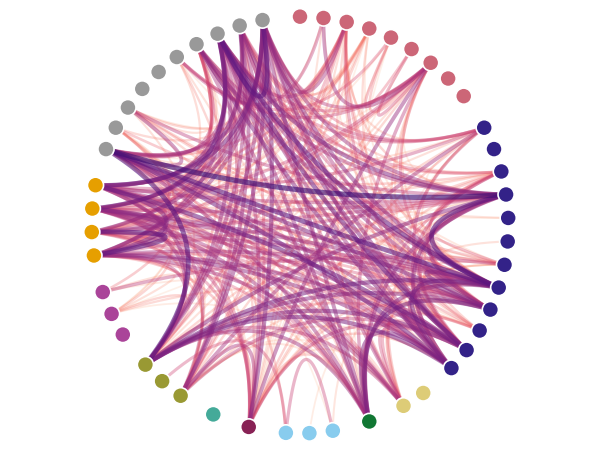

In [16]:
fig = plt.figure(figsize=(4, 3), facecolor='white')
ax = fig.add_axes([0.125, 0, 0.75, 1])                  # a square in the middle
t = int(np.abs(mean_corr - mean_corr.quantile(0.9)).argmin())
on = np.flatnonzero(pairs[:, t] >= CUTOFF)
on = on[np.argsort(pairs[on, t])]
w = (pairs[on, t] - CUTOFF) / (1 - CUTOFF)
colors = EDGE_CMAP(0.2 + 0.7 * w)
colors[:, 3] = 0.15 + 0.6 * w
ax.add_collection(LineCollection(curves[on], colors=colors, linewidths=0.8 + 2 * w))
ax.scatter(*xy.T, s=60, zorder=3,
           c=[color_of[sector[n]] for n in industries], edgecolors='white', linewidths=0.8)
ax.set(xlim=(-1.08, 1.08), ylim=(-1.08, 1.08), aspect='equal')
ax.set_axis_off()
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=150, facecolor='white')
plt.close(fig)
display(Image(buf.getvalue()))

In [17]:
print(f'notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} min')

notebook run time: 1.1 min
